# 🎮 Video Game Sales Analytics — Exploratory Data Analysis

**An end-to-end EDA case study**: data audit → cleaning → descriptive statistics → platform and publisher performance → regional comparisons → Nintendo case study → business insights.

**Research question:** What historical patterns emerge across gaming platforms, genres, publishers, and geographic markets?

> **Data model:** Every row represents a **game-platform entry**. `*_Sales` is in **millions of copies**, not dollars. `Year` is the *release* year, and each sales metric is cumulative lifetime units associated with the title; this is **not a dataset of annual transactions**. The sample excludes low-selling releases.

## 0. Setup

The notebook works when launched from the repository root or from `notebooks/`. Place your source CSV in `data/games.csv` or run `python scripts/download_data.py` from the project root first.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import load_raw, clean_games, quality_report, REGION_COLUMNS
from src.analysis import (
    category_ranking, filter_games, yearly_trend, region_mix,
    nintendo_japan_genres, nintendo_regional_medians, nintendo_sports_peaks,
)

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 20)
print('Project directory:', ROOT)

Project directory: /mnt/data/video-game-sales-analytics


## 1. Data ingestion & basic inspection
First inspect the original source **before deleting rows**. This makes missing-data decisions auditable.

In [2]:
data_path = ROOT / 'data' / 'games.csv'
if not data_path.exists():
    data_path = ROOT / 'data' / 'vgsales.csv'
raw = load_raw(data_path)
display(raw.head())
print('Rows, columns:', raw.shape)
print('Column dtypes:')
display(raw.dtypes.to_frame('dtype'))

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


Rows, columns: (16598, 11)
Column dtypes:


,dtype
Rank,int64
Name,object
Platform,object
Year,float64
Genre,object
Publisher,object
NA_Sales,float64
EU_Sales,float64
JP_Sales,float64
Other_Sales,float64


In [3]:
missing = raw.isna().sum().sort_values(ascending=False)
display(missing.to_frame('missing_values'))
print('Most missing values in a column:', missing.max())
print('Exact duplicate rows:', raw.duplicated().sum())
print('Rank is an ordinal identifier; names and genres are categorical; year is discrete.')

,missing_values
Year,271
Publisher,58
Rank,0
Platform,0
Name,0
Genre,0
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


Most missing values in a column: 271
Exact duplicate rows: 0
Rank is an ordinal identifier; names and genres are categorical; year is discrete.


## 2. Cleaning and validation
Drop incomplete observations, invalid sales and exact duplicates. Keep the source untouched and document how many rows were removed.

In [4]:
games = clean_games(raw)
quality = quality_report(raw, games)
display(pd.DataFrame([quality]).drop(columns=['missing_by_column', 'note']))
print(quality['note'])
assert games.isna().sum().sum() == 0
assert (games[['Global_Sales'] + REGION_COLUMNS] >= 0).all().all()
print('Cleaned shape:', games.shape)

,source_rows,clean_rows,removed_rows,exact_duplicate_rows,regional_sum_difference_max_m,regional_sum_difference_gt_0_05_count
0,16598,16291,307,0,0.02,0


Source sales are rounded; regional totals need not match worldwide values exactly.
Cleaned shape: (16291, 11)


## 3. Release years — descriptive statistics
Count **game-platform entries** by release year. Compare mean, median and mode of `Year`.

In [5]:
display(games['Year'].describe().to_frame('Year'))
print('Mode year(s):', games['Year'].mode().tolist())
print('Mean year:', games['Year'].mean())
print('Median year:', games['Year'].median())
print('Share of records released after 2007: {:.1%}'.format((games['Year'] > 2007).mean()))

,Year
count,16291.000000
mean,2006.405561
std,5.832412
min,1980.000000
25%,2003.000000
50%,2007.000000
75%,2010.000000
max,2020.000000


Mode year(s): [2009]
Mean year: 2006.4055613528942
Median year: 2007.0
Share of records released after 2007: 49.1%


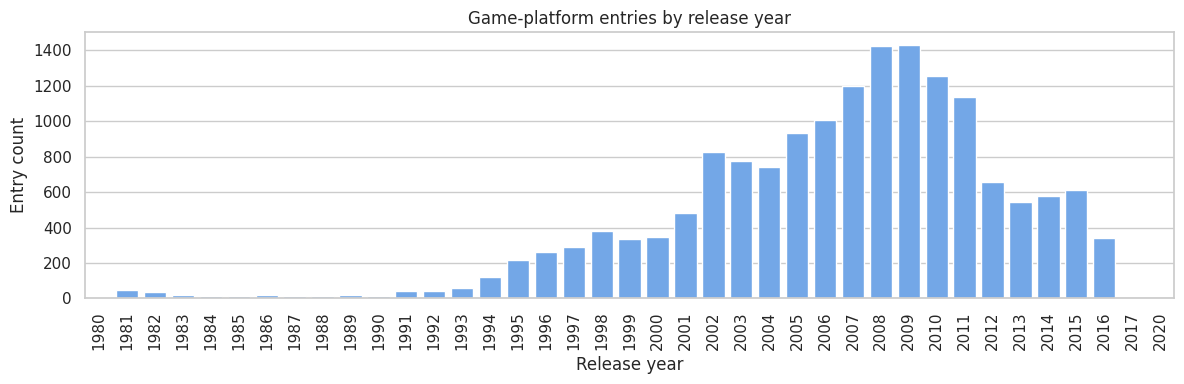

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.countplot(data=games, x='Year', order=sorted(games['Year'].unique()), color='#60a5fa', ax=ax)
ax.set(title='Game-platform entries by release year', xlabel='Release year', ylabel='Entry count')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

## 4. Platforms and publishers
Distinguish **most releases** from **highest lifetime unit sales**. These are different questions.

In [7]:
platform_share = games['Platform'].value_counts(normalize=True).mul(100)
display(platform_share.loc[platform_share > 7].round(2).rename('share_pct').to_frame())
print('Platforms above 7% of entries:', platform_share.loc[platform_share > 7].index.tolist())
display(category_ranking(games, 'Platform', n=10))
display(category_ranking(games, 'Publisher', n=10))

,share_pct
Platform,
DS,13.08
PS2,13.06
PS3,8.0
Wii,7.92
X360,7.57
PSP,7.35
PS,7.3


Platforms above 7% of entries: ['DS', 'PS2', 'PS3', 'Wii', 'X360', 'PSP', 'PS']


,Platform,sales_m,releases
0,PS2,1233.46,2127
1,X360,969.60,1234
2,PS3,949.35,1304
3,Wii,909.81,1290
4,DS,818.91,2131
5,PS,727.39,1189
6,GBA,305.62,786
7,PSP,291.71,1197
8,PS4,278.10,336
9,PC,254.70,938


,Publisher,sales_m,releases
0,Nintendo,1784.43,696
1,Electronic Arts,1093.39,1339
2,Activision,721.41,966
3,Sony Computer Entertainment,607.28,682
4,Ubisoft,473.54,918
5,Take-Two Interactive,399.30,412
6,THQ,340.44,712
7,Konami Digital Entertainment,278.56,823
8,Sega,270.70,632
9,Namco Bandai Games,253.65,928


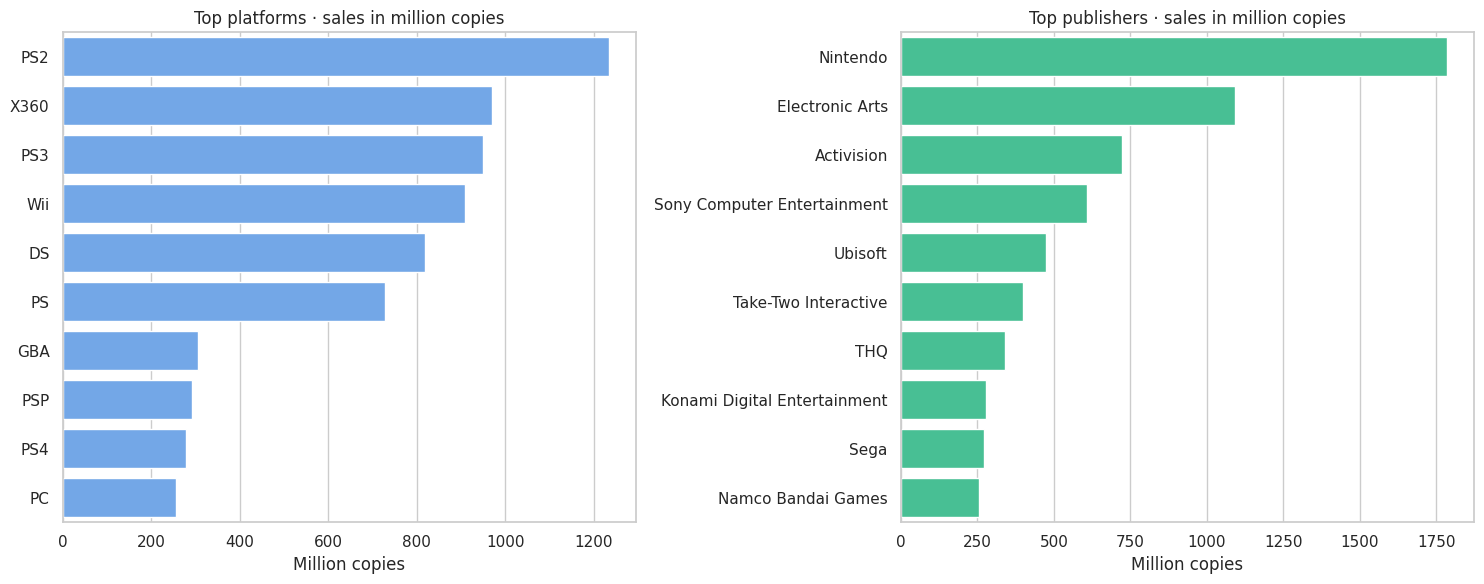

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
platforms = category_ranking(games, 'Platform', n=10)
publishers = category_ranking(games, 'Publisher', n=10)
sns.barplot(data=platforms, y='Platform', x='sales_m', color='#60a5fa', ax=axes[0])
sns.barplot(data=publishers, y='Publisher', x='sales_m', color='#34d399', ax=axes[1])
axes[0].set(title='Top platforms · sales in million copies', xlabel='Million copies', ylabel='')
axes[1].set(title='Top publishers · sales in million copies', xlabel='Million copies', ylabel='')
plt.tight_layout(); plt.show()

## 5. Geographic market share
Compare the four regional components. Do **not** include `Global_Sales` as a fifth region — it is a worldwide total.

,region,sales_m,share_pct
0,North America,4327.65,49.14
1,Europe,2406.69,27.33
2,Japan,1284.27,14.58
3,Other regions,788.91,8.96


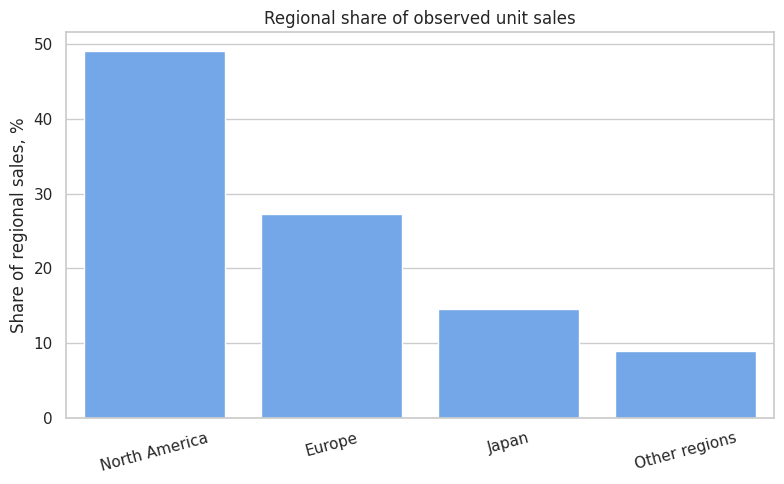

In [9]:
mix = region_mix(games)
display(mix.round(2))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=mix, x='region', y='share_pct', color='#60a5fa', ax=ax)
ax.set(title='Regional share of observed unit sales', xlabel='', ylabel='Share of regional sales, %')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 6. Nintendo: regional sales and genre distributions
Compare *median sales per entry* in NA/EU/JP/Other. For Japan, compare the mean, median and IQR by genre.

In [10]:
nintendo = games.query("Publisher == 'Nintendo'").copy()
print('Nintendo entries:', len(nintendo))
display(nintendo_regional_medians(games).round(3))
print('Highest Nintendo regional median:', nintendo_regional_medians(games).iloc[0]['region'])
np_stats = nintendo_japan_genres(games)
display(np_stats.round(3))

Nintendo entries: 696


,region,median_m
0,North America,0.375
2,Japan,0.280
1,Europe,0.120
3,Other regions,0.030


Highest Nintendo regional median: North America


,Genre,count,mean,median,q1,q3,iqr
0,Fighting,18,0.830,0.500,0.132,1.365,1.232
1,Simulation,28,0.845,0.390,0.073,0.968,0.895
2,Platform,111,0.922,0.540,0.225,1.080,0.855
3,Racing,37,0.790,0.340,0.100,0.890,0.790
4,Misc,100,0.552,0.250,0.050,0.730,0.680
5,Sports,55,0.652,0.250,0.060,0.715,0.655
6,Role-Playing,105,0.971,0.360,0.160,0.740,0.580
7,Puzzle,74,0.501,0.255,0.080,0.602,0.523
8,Strategy,31,0.337,0.190,0.060,0.445,0.385
9,Action,78,0.374,0.170,0.080,0.460,0.380


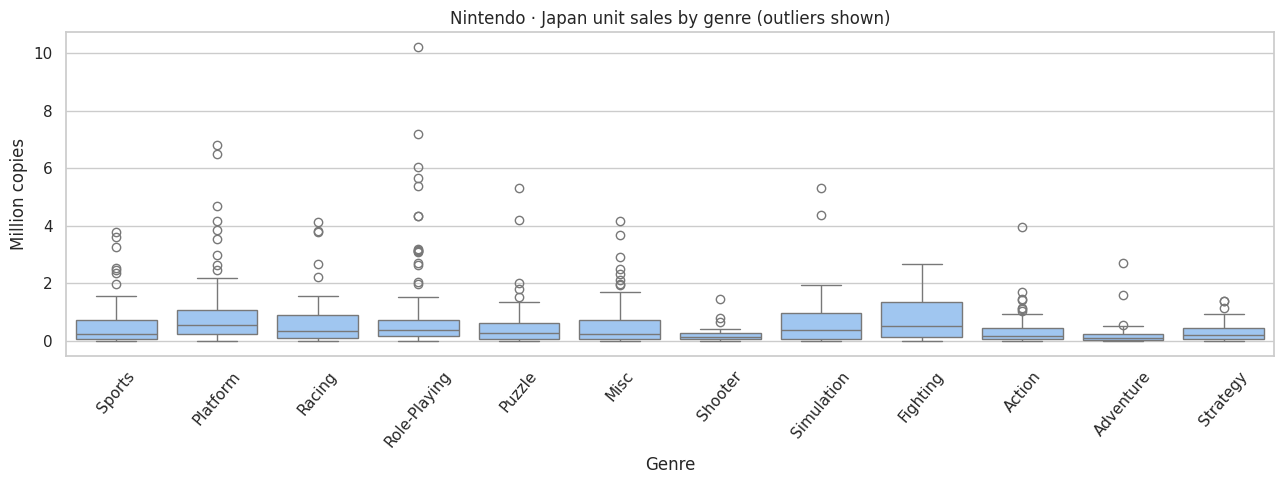

In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=nintendo, x='Genre', y='JP_Sales', color='#93c5fd', ax=ax)
ax.set(title='Nintendo · Japan unit sales by genre (outliers shown)', xlabel='Genre', ylabel='Million copies')
ax.tick_params(axis='x', rotation=50)
plt.tight_layout(); plt.show()

## 7. Nintendo five-genre release-year analysis
Compare `Fighting`, `Simulation`, `Platform`, `Racing`, `Sports` across game release-year cohorts. Summing `Global_Sales` within each cohort shows **lifetime sales of games released in the same year**, not annual sold copies.

,Year,Genre,sales_m
0,1983,Platform,5.62
1,1983,Sports,3.20
2,1984,Racing,5.68
3,1984,Sports,6.18
4,1985,Platform,43.17


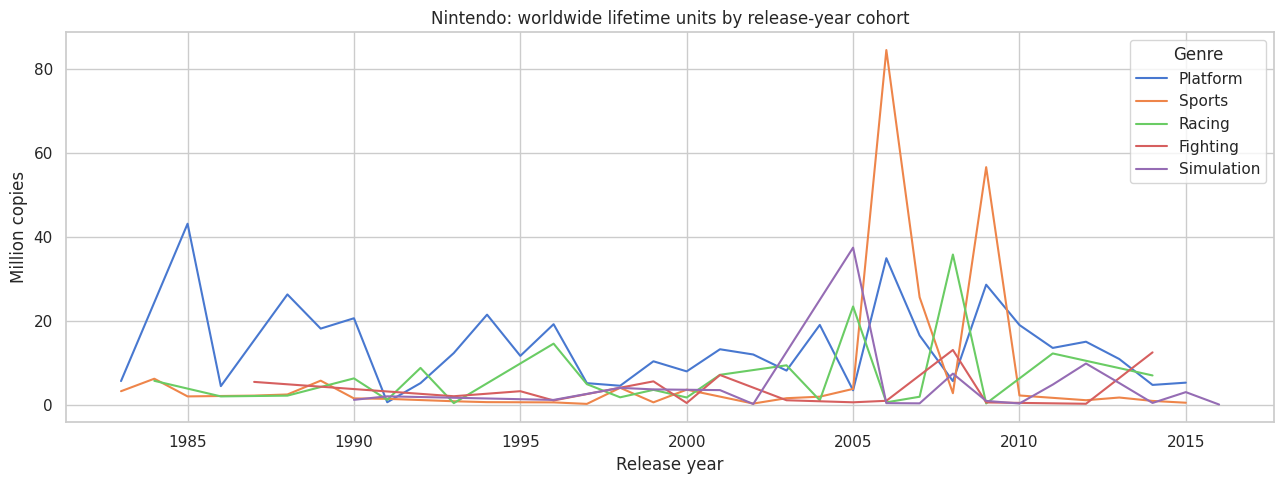

In [12]:
target = ['Fighting', 'Simulation', 'Platform', 'Racing', 'Sports']
five = nintendo[nintendo['Genre'].isin(target)]
genre_cohorts = yearly_trend(five, 'Global_Sales', 'Genre')
display(genre_cohorts.head())
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=genre_cohorts, x='Year', y='sales_m', hue='Genre', ax=ax)
ax.set(title='Nintendo: worldwide lifetime units by release-year cohort', ylabel='Million copies', xlabel='Release year')
plt.tight_layout(); plt.show()

In [13]:
sports_peaks = nintendo_sports_peaks(games, n=10)
display(sports_peaks)
print('Highest Nintendo Sports release-year cohort:', int(sports_peaks.iloc[0]['Year']))

,Year,sales_m
0,2006,84.62
1,2009,56.67
2,2007,25.63
3,1984,6.18
4,1989,5.72
5,1998,4.01
6,2005,3.75
7,2000,3.57
8,1983,3.20
9,2008,2.72


Highest Nintendo Sports release-year cohort: 2006


## 8. Business interpretation
These statements are generated from the data above rather than fixed assumptions. A responsible portfolio analysis should explain what the sample can — and cannot — establish.

In [14]:
top_platform = category_ranking(games, 'Platform', n=1).iloc[0]
top_publisher = category_ranking(games, 'Publisher', n=1).iloc[0]
top_region = mix.sort_values('sales_m', ascending=False).iloc[0]
print(f"Most recorded cumulative unit sales by platform: {top_platform['Platform']} ({top_platform['sales_m']:.2f}M).")
print(f"Most recorded cumulative unit sales by publisher: {top_publisher['Publisher']} ({top_publisher['sales_m']:.2f}M).")
print(f"Largest observed regional market: {top_region['region']} ({top_region['share_pct']:.1f}% of regional sales).")
print(f"Nintendo's largest Japan genre IQR: {np_stats.iloc[0]['Genre']} ({np_stats.iloc[0]['iqr']:.3f}M).")

Most recorded cumulative unit sales by platform: PS2 (1233.46M).
Most recorded cumulative unit sales by publisher: Nintendo (1784.43M).
Largest observed regional market: North America (49.1% of regional sales).
Nintendo's largest Japan genre IQR: Fighting (1.232M).


### Limitations and next steps

1. The source excludes games below the threshold, so platform rankings are **sample rankings**, not a complete industry census.
2. Release-year cohort sales are not sales occurring in that calendar year. **No annual transaction-level forecasts** are justified by these data alone.
3. `Global_Sales` and regional sales measure *copies*, **not money**.
4. Some records share the same game title across multiple platforms.
5. The dataset is historical and does not describe the current market.
6. Dropping incomplete observations introduces a potential selection effect.

**Next steps:** run `streamlit run app.py` for interactive segmentation, `python scripts/generate_report.py` for a written executive summary, and `python scripts/run_sql_analysis.py` for reproducible SQL analysis.

**Source:** Gregory Smith, [Video Games Sales (Zenodo)](https://zenodo.org/records/5898311).